# Artificial Neurons and Single-Layer Neural Networks

## Objectives
- Understand the working of artificial neurons and threshold activation.
- Implement the Perceptron learning algorithm from scratch.
- Implement ADALINE using gradient descent and the delta rule.
- Visualize training errors, cost convergence, and decision boundaries.
- Evaluate model generalization on unseen data and compare the algorithms.

## Dataset
Iris flower dataset -- Setosa and Versicolor classes.

## Advanced extension
Feature standardization, stratified train-test splitting, evaluation metrics, and a comparative analysis of Perceptron and ADALINE.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

In [2]:
iris = load_iris()

X_all = iris.data
y_all = iris.target

print("Dataset shape:", X_all.shape)
print("Feature names:", iris.feature_names)
print("Target classes:", iris.target_names)
print("Class distribution:", np.bincount(y_all))

Dataset shape: (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: ['setosa' 'versicolor' 'virginica']
Class distribution: [50 50 50]


In [3]:
mask = y_all < 2

X = X_all[mask][:, [0, 2]]
y = np.where(y_all[mask] == 0, -1, 1)

feature_names = ["Sepal length (cm)", "Petal length (cm)"]

df = pd.DataFrame(X, columns=feature_names)
df["target"] = np.where(y == -1, "Setosa", "Versicolor")

display(df.head())
print("\nNumber of samples:", len(X))
print("Class counts:", pd.Series(df["target"]).value_counts())

,Sepal length (cm),Petal length (cm),target
0,5.1,1.4,Setosa
1,4.9,1.4,Setosa
2,4.7,1.3,Setosa
3,4.6,1.5,Setosa
4,5.0,1.4,Setosa



Number of samples: 100
Class counts: target
Setosa        50
Versicolor    50
Name: count, dtype: int64


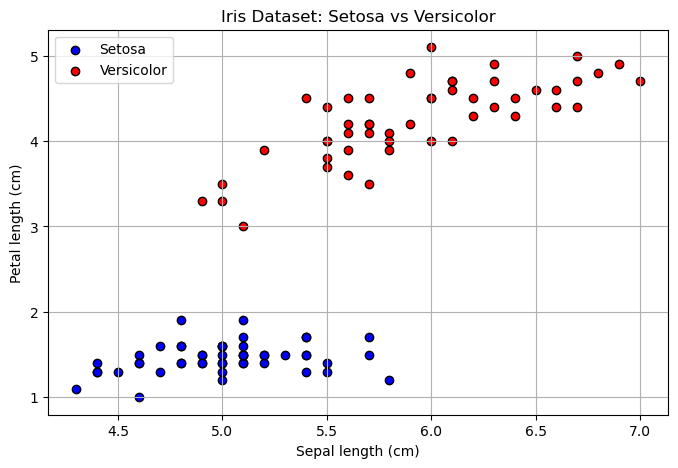

In [4]:
plt.figure()
for label, color, name in [
    (-1, "blue", "Setosa"),
    (1, "red", "Versicolor")
]:
    plt.scatter(
        X[y == label, 0],
        X[y == label, 1],
        color=color,
        label=name,
        edgecolor="black"
    )

plt.xlabel(feature_names[0])
plt.ylabel(feature_names[1])
plt.title("Iris Dataset: Setosa vs Versicolor")
plt.legend()
plt.show()

In [5]:
class Perceptron:
    def __init__(self, eta=0.01, epochs=50):
        self.eta = eta
        self.epochs = epochs

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0, 1, -1)

    def fit(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.epochs):
            errors = 0

            for xi, target in zip(X, y):
                update = self.eta * (
                    target - self.predict(xi)
                )

                self.w_[1:] += update * xi
                self.w_[0] += update

                errors += int(update != 0.0)

            self.errors_.append(errors)

        return self

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training class counts:", np.unique(y_train, return_counts=True))
print("Testing class counts:", np.unique(y_test, return_counts=True))

Training samples: 80
Testing samples: 20
Training class counts: (array([-1,  1]), array([40, 40]))
Testing class counts: (array([-1,  1]), array([10, 10]))


In [7]:
ppn = Perceptron(eta=0.01, epochs=50)
ppn.fit(X_train_scaled, y_train)

y_pred_ppn = ppn.predict(X_test_scaled)

print("Learned weights:", ppn.w_)
print("Training errors in final epoch:", ppn.errors_[-1])
print("Test accuracy:", round(accuracy_score(y_test, y_pred_ppn) * 100, 2), "%")

Learned weights: [0.02       0.02407583 0.05659118]
Training errors in final epoch: 0
Test accuracy: 100.0 %


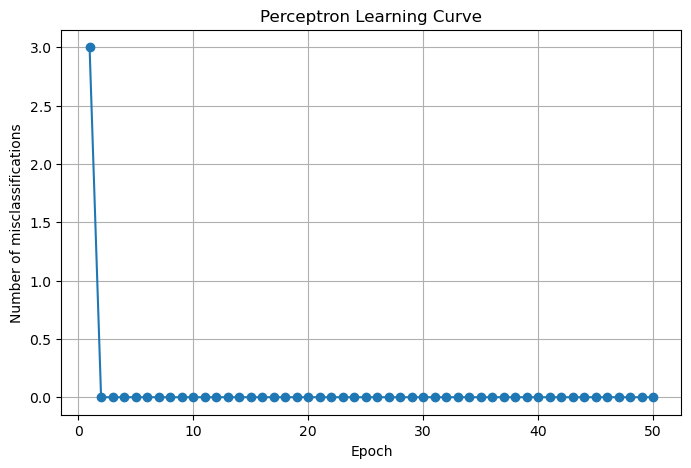

In [8]:
plt.figure()
plt.plot(
    range(1, len(ppn.errors_) + 1),
    ppn.errors_,
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Number of misclassifications")
plt.title("Perceptron Learning Curve")
plt.show()

In [9]:
class AdalineGD:
    def __init__(self, eta=0.01, epochs=50):
        self.eta = eta
        self.epochs = epochs

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def activation(self, X):
        return self.net_input(X)

    def predict(self, X):
        return np.where(self.activation(X) >= 0, 1, -1)

    def fit(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.cost_ = []

        for _ in range(self.epochs):
            output = self.activation(X)
            errors = y - output

            self.w_[1:] += (
                self.eta * X.T.dot(errors) / len(y)
            )
            self.w_[0] += self.eta * errors.mean()

            cost = (errors ** 2).mean() / 2
            self.cost_.append(cost)

        return self

In [10]:
ada = AdalineGD(eta=0.01, epochs=50)
ada.fit(X_train_scaled, y_train)

y_pred_ada = ada.predict(X_test_scaled)

print("Learned weights:", ada.w_)
print("Final training cost:", round(ada.cost_[-1], 6))
print("Test accuracy:", round(accuracy_score(y_test, y_pred_ada) * 100, 2), "%")

Learned weights: [1.99340544e-16 2.36535823e-01 3.35902882e-01]
Final training cost: 0.145235
Test accuracy: 90.0 %


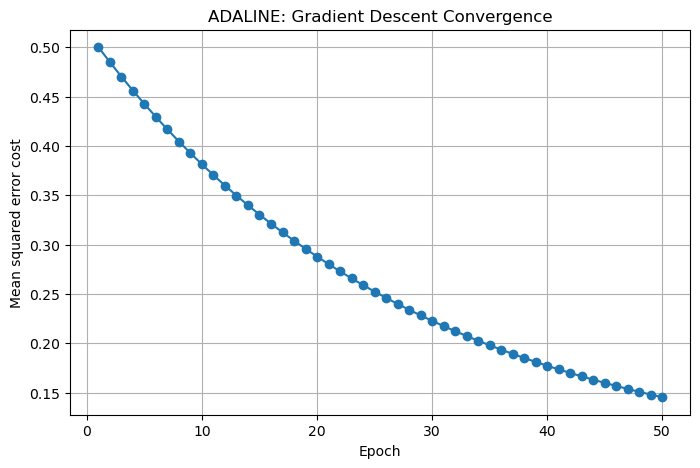

In [11]:
plt.figure()
plt.plot(
    range(1, len(ada.cost_) + 1),
    ada.cost_,
    marker="o"
)
plt.xlabel("Epoch")
plt.ylabel("Mean squared error cost")
plt.title("ADALINE: Gradient Descent Convergence")
plt.show()

In [12]:
class AdalineSGD:
    def __init__(self, eta=0.01, epochs=50, shuffle=True):
        self.eta = eta
        self.epochs = epochs
        self.shuffle = shuffle

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0, 1, -1)

    def fit(self, X, y):
        self.w_ = np.zeros(1 + X.shape[1])
        self.cost_ = []

        for _ in range(self.epochs):
            if self.shuffle:
                indices = np.random.permutation(len(y))
                X_epoch, y_epoch = X[indices], y[indices]
            else:
                X_epoch, y_epoch = X, y

            costs = []

            for xi, target in zip(X_epoch, y_epoch):
                output = np.dot(xi, self.w_[1:]) + self.w_[0]
                error = target - output

                self.w_[1:] += self.eta * xi * error
                self.w_[0] += self.eta * error

                costs.append(error ** 2 / 2)

            self.cost_.append(np.mean(costs))

        return self

SGD ADALINE test accuracy: 100.0 %


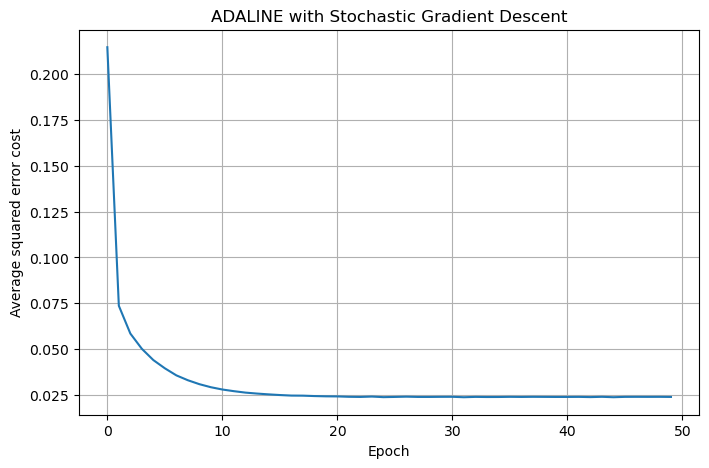

In [13]:
ada_sgd = AdalineSGD(
    eta=0.01,
    epochs=50,
    shuffle=True
)

ada_sgd.fit(X_train_scaled, y_train)
y_pred_sgd = ada_sgd.predict(X_test_scaled)

print(
    "SGD ADALINE test accuracy:",
    round(accuracy_score(y_test, y_pred_sgd) * 100, 2),
    "%"
)

plt.figure()
plt.plot(ada_sgd.cost_)
plt.xlabel("Epoch")
plt.ylabel("Average squared error cost")
plt.title("ADALINE with Stochastic Gradient Descent")
plt.show()

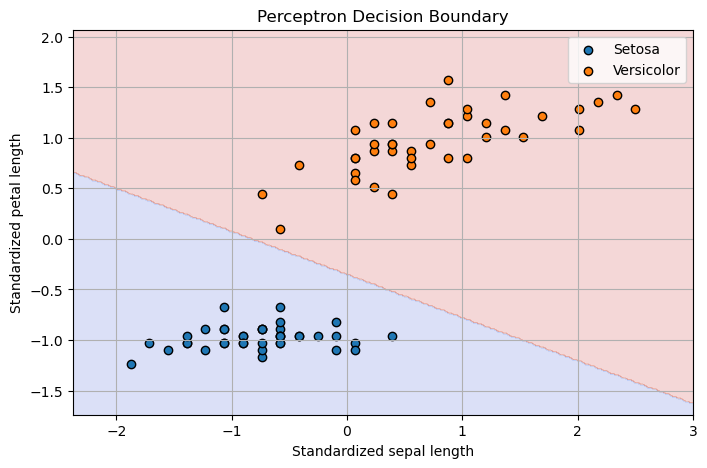

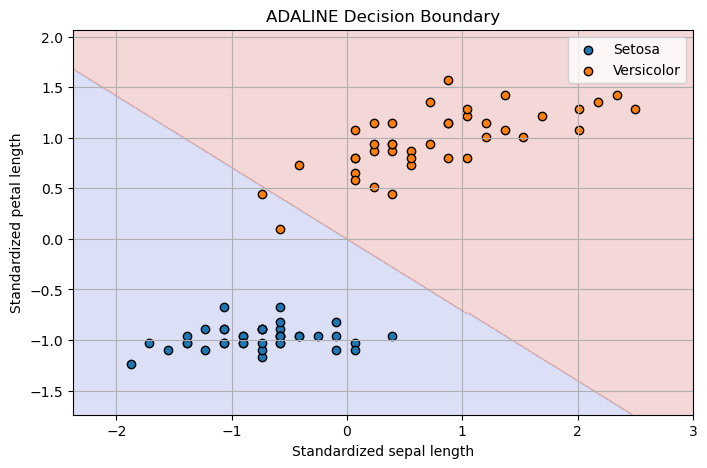

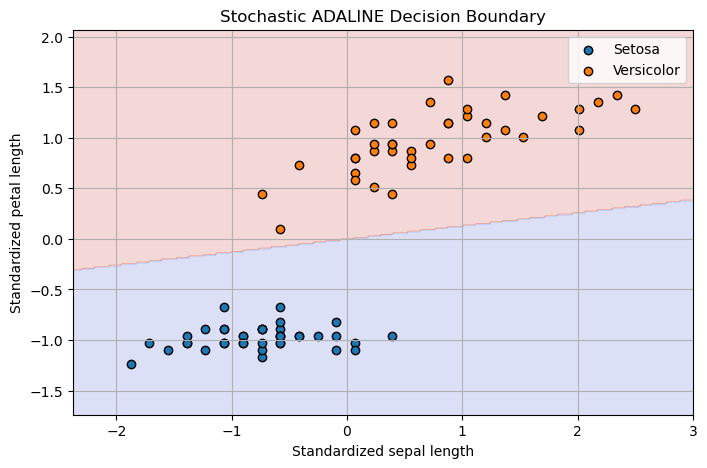

In [14]:
def plot_decision_boundary(X, y, model, title):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    Z = model.predict(grid).reshape(xx.shape)

    plt.figure()
    plt.contourf(xx, yy, Z, alpha=0.2, cmap="coolwarm")
    plt.scatter(
        X[y == -1, 0], X[y == -1, 1],
        label="Setosa", edgecolor="black"
    )
    plt.scatter(
        X[y == 1, 0], X[y == 1, 1],
        label="Versicolor", edgecolor="black"
    )
    plt.xlabel("Standardized sepal length")
    plt.ylabel("Standardized petal length")
    plt.title(title)
    plt.legend()
    plt.show()


plot_decision_boundary(
    X_train_scaled, y_train, ppn,
    "Perceptron Decision Boundary"
)

plot_decision_boundary(
    X_train_scaled, y_train, ada,
    "ADALINE Decision Boundary"
)

plot_decision_boundary(
    X_train_scaled, y_train, ada_sgd,
    "Stochastic ADALINE Decision Boundary"
)

In [15]:
models = {
    "Perceptron": (ppn, y_pred_ppn),
    "ADALINE Batch GD": (ada, y_pred_ada),
    "ADALINE SGD": (ada_sgd, y_pred_sgd)
}

results = []

for name, (model, predictions) in models.items():
    results.append({
        "Model": name,
        "Test Accuracy (%)": round(
            accuracy_score(y_test, predictions) * 100, 2
        ),
        "Misclassified Samples": int(
            np.sum(y_test != predictions)
        )
    })

results_df = pd.DataFrame(results)
display(results_df)

,Model,Test Accuracy (%),Misclassified Samples
0,Perceptron,100.0,0
1,ADALINE Batch GD,90.0,2
2,ADALINE SGD,100.0,0


In [16]:
for name, (_, predictions) in models.items():
    print(f"\n{name}")
    print("-" * len(name))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, predictions, labels=[-1, 1]))
    print("\nClassification report:")
    print(classification_report(
        y_test,
        predictions,
        labels=[-1, 1],
        target_names=["Setosa", "Versicolor"],
        zero_division=0
    ))


Perceptron
----------
Confusion matrix:
[[10  0]
 [ 0 10]]

Classification report:
              precision    recall  f1-score   support

      Setosa       1.00      1.00      1.00        10
  Versicolor       1.00      1.00      1.00        10

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


ADALINE Batch GD
----------------
Confusion matrix:
[[10  0]
 [ 2  8]]

Classification report:
              precision    recall  f1-score   support

      Setosa       0.83      1.00      0.91        10
  Versicolor       1.00      0.80      0.89        10

    accuracy                           0.90        20
   macro avg       0.92      0.90      0.90        20
weighted avg       0.92      0.90      0.90        20


ADALINE SGD
-----------
Confusion matrix:
[[10  0]
 [ 0 10]]

Classification report:
              precision    recall  f1-score   support

      Setosa       1.00  

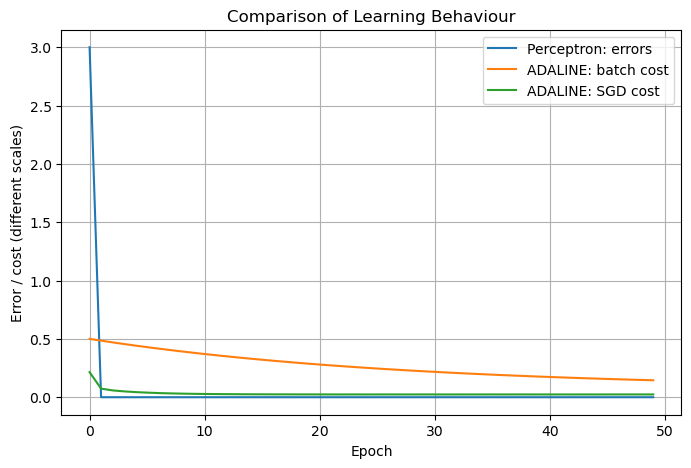

In [17]:
plt.figure()

plt.plot(ppn.errors_, label="Perceptron: errors")
plt.plot(ada.cost_, label="ADALINE: batch cost")
plt.plot(ada_sgd.cost_, label="ADALINE: SGD cost")

plt.xlabel("Epoch")
plt.ylabel("Error / cost (different scales)")
plt.title("Comparison of Learning Behaviour")
plt.legend()
plt.show()

In [18]:
best_model = results_df.loc[
    results_df["Test Accuracy (%)"].idxmax()
]

print("Model comparison:")
display(results_df)

print("\nHighest test accuracy in this run:")
print(best_model["Model"])
print(f"Accuracy: {best_model['Test Accuracy (%)']}%")

print("\nKey observations:")
print("1. The Perceptron learns through classification errors.")
print("2. ADALINE minimizes a continuous squared-error cost.")
print("3. Stochastic gradient descent updates weights sample by sample.")
print("4. Feature standardization improves numerical stability.")
print("5. Test accuracy measures performance on unseen samples.")

Model comparison:


,Model,Test Accuracy (%),Misclassified Samples
0,Perceptron,100.0,0
1,ADALINE Batch GD,90.0,2
2,ADALINE SGD,100.0,0



Highest test accuracy in this run:
Perceptron
Accuracy: 100.0%

Key observations:
1. The Perceptron learns through classification errors.
2. ADALINE minimizes a continuous squared-error cost.
3. Stochastic gradient descent updates weights sample by sample.
4. Feature standardization improves numerical stability.
5. Test accuracy measures performance on unseen samples.


## Conclusion

The Perceptron and ADALINE algorithms were implemented from scratch using NumPy and evaluated on the Iris dataset. The Perceptron used a threshold activation function and an error-driven weight update rule, whereas ADALINE minimized mean squared error through gradient descent. Stochastic gradient descent was also implemented to demonstrate sample-wise weight updates. The extended experiment incorporated feature standardization, a stratified train-test split, decision-boundary visualization, and quantitative evaluation. This experiment demonstrates the fundamental principles of single-layer neural networks and the differences between classification-based learning and gradient-based optimization.